<a href="https://colab.research.google.com/github/ZainabIftikhar1204/DL-for-Space-Time-and-Graphs---Assignment-2/blob/main/DL_STG_Assg_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 2 AHHH

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision

In [91]:
def rotate(data, rotations=1):
  # Apply requested number of 90-degree rotations (k = 0, 1, 2, 3, 4)
  if rotations % 4 != 0:
    data = torch.rot90(data, k=rotations % 4, dims=[-2, -1])
  return data

In [90]:
def mirror(data, mirror=1):
  # Apply horizontal mirroring efficiently:
  # Flipping an even number of times does nothing. An odd number of times is equal to a single flip.
  if mirror % 2 != 0:
    data = torch.flip(data, dims=[-1])
  return data

In [97]:
def speed_up(data, stride = 1):
  data = data[::speed_up]
  return data

In [98]:
def transform_data(data, stride=1, rotations=0, mirror=0):
  # Convert the video sequence to float32 and normalize
  data = data.float() / 255.0
  # Speed up / stride
  data = speed_up(data, stride)
  #mirror
  data = mirror(data, mirror)
  #rotate
  data = rotate(data, rotations)

  return data

In [84]:
# lets load the data shall we?
data = torchvision.datasets.MovingMNIST(root='./data',
                                        download=True,
                                        split=None,
                                        transform=lambda x: transform_data(x, speed_up=1)
                                        )
data

Dataset MovingMNIST
    Number of datapoints: 10000
    Root location: ./data
    StandardTransform
Transform: <function <lambda> at 0x78e1d7912980>

In [68]:
import torch
from torch.utils.data import Subset

# Define your split sizes or specific indices
total_size = len(data)
train_size = 8000
val_size = 1000

# Generate indices
indices = torch.randperm(total_size).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

# Create Subsets
train_dataset = Subset(data, train_indices)
val_dataset = Subset(data, val_indices)
test_dataset = Subset(data, test_indices)

print(f"Train size: {len(train_dataset)}")
print(f"Validation size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train size: 8000
Validation size: 1000
Test size: 1000


In [54]:
train_dataset.dataset.data[0][0]

tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]], dtype=torch.uint8)

In [55]:
# Let's check the shape of the underlying data
print("Underlying raw data shape:", data.data.shape)

# Let's inspect a single sequence from the dataset
first_sequence = data[0]
print("Single dataset item shape/length:", first_sequence.shape if torch.is_tensor(first_sequence) else len(first_sequence))

Underlying raw data shape: torch.Size([10000, 20, 1, 64, 64])
Single dataset item shape/length: torch.Size([20, 1, 64, 64])


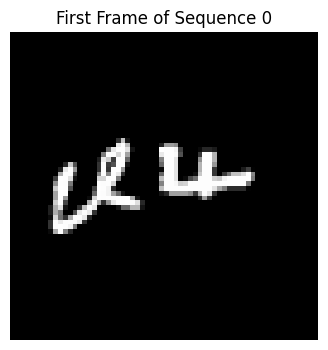

In [56]:
# Extract the 1st sequence: shape is (20, 1, 64, 64)
video_sequence = data[0]

# Extract the 1st frame: shape is (1, 64, 64)
first_frame = video_sequence[0]

# Plot the frame using Matplotlib
plt.figure(figsize=(4, 4))
plt.imshow(first_frame.squeeze(), cmap='gray')
plt.title("First Frame of Sequence 0")
plt.axis('off')
plt.show()

In [85]:
## Checking if transformations are right or if i messed up
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7,0,10,20] = 1

In [86]:
# check (a): max|M (M (x)) − x|
x_mm = mirror(x, 2)
torch.abs(x_mm - x).max()

tensor(0.)

In [87]:
# check (b):max|R4 (x) − x|
x_r4 = rotate(x, 4)
torch.abs(x_r4 - x).max()

tensor(0.)

In [92]:
#check (c): max|M RM (x) − R−1 (x)|
x_mrm = mirror(rotate(mirror(x), 1))
x_r_inv = rotate(x, -1)
torch.abs(x_mrm - x_r_inv).max()

tensor(0.)

In [95]:
#check(d):bright pixel of M (p) (frame, row, column)
m_p = mirror(p)

# Find the value and the flat index of the maximum element
max_val = torch.max(m_p)
max_idx = torch.argmax(m_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# m_p shape is [20, 1, 64, 64]
shape = m_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")


Maximum pixel value: 1.0
Coordinates - (7, 10, 43)


In [96]:
#check (e): bright pixel of R(p) (frame, row, column)
r_p = rotate(p, 1)

# Find the value and the flat index of the maximum element
max_val = torch.max(r_p)
max_idx = torch.argmax(r_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# r_p shape is [20, 1, 64, 64]
shape = r_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")

Maximum pixel value: 1.0
Coordinates - (7, 43, 10)


In [35]:
LOOKBACK = 5
HORIZON = 5

In [105]:
# 1. Grab a raw 20-frame sequence (bypassing dataset transform for demonstration)
raw_sequence = data.data[0] # shape: [20, 1, 64, 64]
print(f"Raw sequence shape: {raw_sequence.shape} (20 frames)")

# 2. Apply a speedup (e.g. stride = 2) to get 10 frames
stride_vals = [1, 2, 3]

for stride_val in stride_vals:
  print(f"\n----------STRIDE: {stride_val}------------")
  transformed_seq = raw_sequence[::stride_val]

  lookback_frames = transformed_seq[:LOOKBACK]
  target_frames = transformed_seq[LOOKBACK:LOOKBACK + HORIZON]

  print(f"Lookback Frames: {len(lookback_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK)]}")

  print(f"\nTarget / Horizon Frames: {len(target_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK, LOOKBACK + HORIZON)]}")

Raw sequence shape: torch.Size([20, 1, 64, 64]) (20 frames)

----------STRIDE: 1------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 2, 3, 4, 5]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [6, 7, 8, 9, 10]

----------STRIDE: 2------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 3, 5, 7, 9]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [11, 13, 15, 17, 19]

----------STRIDE: 3------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 4, 7, 10, 13]

Target / Horizon Frames: 2
Iindices from original raw 20 frames: [16, 19, 22, 25, 28]
